# Requirements

Incase kaggle api is not linked to your google collab

In [ ]:
!pip install kaggle

In [ ]:
from google.colab import files
files.upload()
# Then select the 'kaggle.json' file from your local machine and upload it.

{}

In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Copy the dataset API command

In [ ]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

100% 2.29G/2.29G [00:25<00:00, 110MB/s]
100% 2.29G/2.29G [00:26<00:00, 94.6MB/s]


In [ ]:
!unzip -q /content/chest-xray-pneumonia.zip

Importing Libraries and Modules

In [ ]:
import os
import cv2
import glob
import h5py
import shutil

import imgaug as aug
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import imgaug.augmenters as iaa

from skimage.io import imread
from skimage.transform import resize
from sklearn.metrics import confusion_matrix
from mlxtend.plotting import plot_confusion_matrix
from sklearn.model_selection import train_test_split

import tensorflow as tf
print(tf.__version__)

from keras.models import Sequential, Model, load_model
from keras.applications.resnet50 import ResNet50, preprocess_input
from keras.layers import Conv2D, MaxPooling2D, Dense, Dropout
from keras.layers import Input, Flatten, SeparableConv2D, BatchNormalization
from keras.optimizers import Adam, SGD, RMSprop
from keras.callbacks import ModelCheckpoint, Callback, EarlyStopping
from keras.utils import to_categorical
from keras import backend as K

color = sns.color_palette()
%matplotlib inline
%config InlineBackend.figure_format="svg"

from PIL import Image, ImageFilter
from concurrent.futures import ProcessPoolExecutor

print("All modules and classes are available.")

2.14.0
All modules and classes are available.


In [ ]:
# Set the seed for hash based operations in python
os.environ['PYTHONHASHSEED'] = '0'

# making values deterministic
seed=1234
np.random.seed(seed)
tf.random.set_seed(seed)
aug.seed(seed)

# Data Preparation

In [ ]:
# Defining some paths..as usual!

data_dir = '/content/chest_xray/chest_xray/'
train_dir = '/content/chest_xray/chest_xray/train/'
val_dir = '/content/chest_xray/chest_xray/val/'
test_dir = '/content/chest_xray/chest_xray/test/'

There are two classes in the dataset Normal and Pneumonia and for each class, we have some samples stored in the corresponding folder. We will store the names of these images and the corresponding label in a pandas dataframe to make life easy.

In [ ]:
normal_cases_dir = '/content/chest_xray/chest_xray/train/NORMAL/'
pneumonia_cases_dir = '/content/chest_xray/chest_xray/train/PNEUMONIA/'

# list of all the images
normal_cases = [f for f in os.listdir(normal_cases_dir) if f.lower().endswith((".jpg", ".png", ".jpeg", ".bmp", ".gif"))]
pneumonia_cases = [f for f in os.listdir(pneumonia_cases_dir) if f.lower().endswith((".jpg", ".png", ".jpeg", ".bmp", ".gif"))]

train_df = []

# Normal cases => 0
# Pnemonia cases => 1

for img in normal_cases:
    train_df.append((normal_cases_dir + str(img),0))

for img in pneumonia_cases:
    train_df.append((pneumonia_cases_dir + str(img), 1))

train_df = pd.DataFrame(train_df, columns=['image', 'label'],index=None)

# Shuffle the data
train_df = train_df.sample(frac=1.).reset_index(drop=True)

train_df.head()

,image,label
0,/content/chest_xray/chest_xray/train/NORMAL/IM...,0
1,/content/chest_xray/chest_xray/train/PNEUMONIA...,1
2,/content/chest_xray/chest_xray/train/PNEUMONIA...,1
3,/content/chest_xray/chest_xray/train/NORMAL/NO...,0
4,/content/chest_xray/chest_xray/train/PNEUMONIA...,1


In [ ]:
print(normal_cases)

['IM-0555-0001-0001.jpeg', 'NORMAL2-IM-0663-0001.jpeg', 'IM-0706-0001.jpeg', 'IM-0618-0001-0002.jpeg', 'NORMAL2-IM-0587-0001-0001.jpeg', 'IM-0519-0001-0001.jpeg', 'IM-0327-0001.jpeg', 'IM-0612-0001.jpeg', 'NORMAL2-IM-0665-0001.jpeg', 'NORMAL2-IM-0946-0001.jpeg', 'NORMAL2-IM-0643-0001.jpeg', 'NORMAL2-IM-1120-0001.jpeg', 'NORMAL2-IM-1196-0001.jpeg', 'NORMAL2-IM-1236-0001.jpeg', 'NORMAL2-IM-0439-0001.jpeg', 'IM-0741-0001.jpeg', 'IM-0487-0001.jpeg', 'IM-0714-0001.jpeg', 'NORMAL2-IM-0521-0001.jpeg', 'IM-0643-0001.jpeg', 'NORMAL2-IM-0775-0001.jpeg', 'NORMAL2-IM-1181-0001.jpeg', 'NORMAL2-IM-0626-0001.jpeg', 'NORMAL2-IM-1116-0001.jpeg', 'NORMAL2-IM-1302-0001.jpeg', 'NORMAL2-IM-0741-0001.jpeg', 'IM-0721-0001.jpeg', 'NORMAL2-IM-0936-0001.jpeg', 'IM-0261-0001.jpeg', 'IM-0707-0001.jpeg', 'IM-0302-0001.jpeg', 'NORMAL2-IM-0473-0001.jpeg', 'IM-0640-0001-0002.jpeg', 'NORMAL2-IM-1156-0001.jpeg', 'IM-0736-0001.jpeg', 'NORMAL2-IM-0599-0001.jpeg', 'IM-0626-0001-0001.jpeg', 'NORMAL2-IM-0854-0001.jpeg', 'NO

1    3875
0    1341
Name: label, dtype: int64


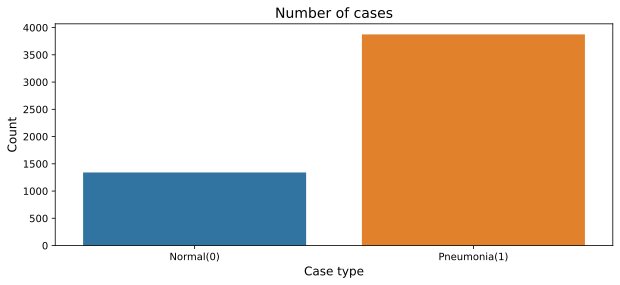

In [ ]:
# Get the counts for each class
cases_count = train_df['label'].value_counts()
print(cases_count)

# Plot the results
plt.figure(figsize=(10,4))
sns.barplot(x=cases_count.index, y= cases_count.values)
plt.title('Number of cases', fontsize=14)
plt.xlabel('Case type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(range(len(cases_count.index)), ['Normal(0)', 'Pneumonia(1)'])
plt.show()

You can see the imbalance between the classes here. The ratio is almost 1:3. Let us take a look at a few samples from each class.

In [ ]:
pneumonia_samples = (train_df[train_df['label']==1]['image'].iloc[:5]).tolist()
normal_samples = (train_df[train_df['label']==0]['image'].iloc[:5]).tolist()

samples = pneumonia_samples + normal_samples
del pneumonia_samples, normal_samples


In [ ]:
samples[0]

'/content/chest_xray/chest_xray/train/PNEUMONIA/person570_virus_1112.jpeg'

In [ ]:
if os.path.exists('/content/chest_xray/chest_xray/train/PNEUMONIA/person1607_virus_2785.jpeg'):
  print("File exists")
else:
  print("don't exist")

File exists


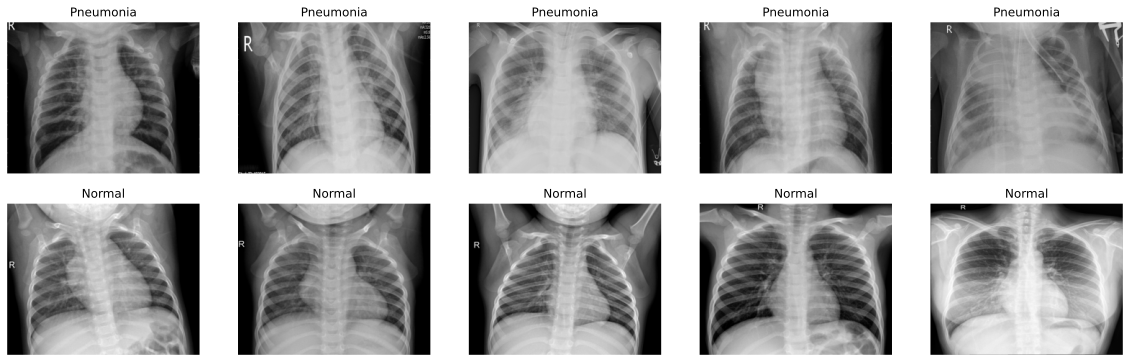

In [ ]:
# Plot the data
f, ax = plt.subplots(2,5, figsize=(20,6))
for i in range(10):
    img = imread(samples[i])
    ax[i//5, i%5].imshow(img, cmap='gray')
    if i<5:
        ax[i//5, i%5].set_title("Pneumonia")
    else:
        ax[i//5, i%5].set_title("Normal")
    ax[i//5, i%5].axis('off')
    ax[i//5, i%5].set_aspect('auto')
plt.show()

# Data Augmentation

Next, we will define our **augmentations** that we are going to apply to the samples during the training process. At this point, I will stick to just two types of augmentations:
* Flip right
* Random rotation

In [ ]:
# Augmentation sequence
seq = iaa.OneOf([
    iaa.Fliplr(),
    iaa.Affine(rotate=30)])

img_rows, img_cols, img_channels = 224,224,3
batch_size=16

# Loss Function

Focal Loss is a specialized loss function designed to address class imbalance in binary classification problems, particularly in scenarios where one class (the negative class) significantly outnumbers the other class (the positive class). Focal Loss was introduced in the paper titled "Focal Loss for Dense Object Detection" by Lin et al. (2017) and has since been used in various computer vision applications, such as object detection and image segmentation.

The key characteristics of Focal Loss are as follows:

Mitigating Class Imbalance: Focal Loss is specifically designed to mitigate the problem of class imbalance by giving more weight to hard-to-classify examples (those with higher prediction errors). This is achieved by modifying the standard binary cross-entropy loss, which treats all misclassified examples equally.

Modulating Loss Weights: The loss function introduces a modulating factor that downweights the contribution of easy-to-classify examples (correctly classified with high confidence). This makes the loss more focused on samples that are difficult to classify.

Two Hyperparameters: Focal Loss introduces two hyperparameters: γ (gamma) and α (alpha).

γ (gamma) controls the rate at which the loss focuses on hard examples. A higher value of γ makes the loss concentrate more on hard examples.

α (alpha) addresses class imbalance. It assigns different weights to positive and negative examples. Typically, α is set to balance the contribution of positive and negative classes.

The formulation of Focal Loss is as follows:

*f(pₜ) = -αₜ  (1 - pₜ)ʳ  log(pₜ)*

Where:

*f(pₜ)* : is the focal loss for a single example.

*pₜ* : is the model's predicted probability for the positive class.

*αₜ* : is the weight assigned to the example based on its class (positive or negative) and its predicted probability.

Focal Loss helps models focus on challenging examples, leading to improved performance in tasks with class imbalance, such as object detection where there are many background (negative) examples and relatively few objects (positive examples). It has become a valuable tool in the field of deep learning for computer vision.

I've also added clip function to prediction values:

*clip(x, a, b) = min(max(x, a), b)*

x is the input tensor.

a is the lower bound value.

b is the upper bound value.

This operation is commonly used to ensure that values in tensors do not become too small or too large, which can lead to numerical instability in mathematical operations.

Here, it is used used to ensure that y_pred values are within a small neighborhood of 0 and 1, preventing them from being too extreme to avoid numerical instability.

*What issues are solved by this?*

**Underflow**: When values become too small, they may approach the limits of numerical precision. This can lead to underflow errors, where small values are treated as zero, causing loss of information and inaccurate results.

**Loss of Significance**: In numerical calculations, significant digits can be lost when subtracting two nearly equal numbers. This can result in a loss of precision and introduce errors into the calculation.

**Ill-Conditioned Problems**: In some mathematical problems, small changes in the input can lead to large changes in the output. This is known as an ill-conditioned problem. Numerical instability can exacerbate issues in such problems.

In [ ]:
# clip function

def clip(x, min_value, max_value):
  return K.minimum(K.maximum(x, min_value), max_value)

In [ ]:
# focal loss
def focal_loss(alpha=0.25,gamma=2.0):
    def focal_crossentropy(y_true, y_pred):
        bce = K.binary_crossentropy(y_true, y_pred)

        y_pred = K.clip(y_pred, K.epsilon(), 1.- K.epsilon())
        p_t = (y_true*y_pred) + ((1-y_true)*(1-y_pred))

        alpha_factor = 1
        modulating_factor = 1

        alpha_factor = y_true*alpha + ((1-alpha)*(1-y_true))
        modulating_factor = K.pow((1-p_t), gamma)

        # compute the final loss and return
        return K.mean(alpha_factor*modulating_factor*bce, axis=-1)
    return focal_crossentropy

# Training

Define a training data generator.

In [ ]:
def data_generator(data, batch_size):
    n = len(data)
    nb_batches = int(np.ceil(n/batch_size))

    indices = np.arange(n)

    batch_data = np.zeros((batch_size, img_rows, img_cols, img_channels), dtype=np.float32)
    batch_labels = np.zeros((batch_size,), dtype=np.float32)

    while True:
        # shuffle indices for the training data
        np.random.shuffle(indices)

        for i in range(nb_batches):
            next_batch_indices = indices[i*batch_size:(i+1)*batch_size]

            # process the next batch
            for j, idx in enumerate(next_batch_indices):
                img = cv2.imread(data.iloc[idx]["image"])
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = seq.augment_image(img)
                img = cv2.resize(img, (img_rows, img_cols)).astype(np.float32)
                label = data.iloc[idx]["label"]

                batch_data[j] = img
                batch_labels[j] = label

            batch_data = preprocess_input(batch_data)
            yield batch_data, batch_labels

In [ ]:
# training data generator
train_data_gen = data_generator(train_df, batch_size)

In [ ]:
def read_images(dir_path, images, label):
    data = []
    for img in images:
        img = cv2.imread(dir_path + str(img))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (img_rows, img_cols)).astype(np.float32)
        data.append(img)

    labels = [label]*len(data)
    data = np.array(data).astype(np.float32)
    data = preprocess_input(data)
    return data, labels

In [ ]:
def prepare_data(data_dir):

    normal_cases_dir = data_dir + 'NORMAL/'
    pneumonia_cases_dir = data_dir + 'PNEUMONIA/'

    normal_cases = [f for f in os.listdir(normal_cases_dir) if f.lower().endswith((".jpg", ".png", ".jpeg", ".bmp", ".gif"))]
    pneumonia_cases = [f for f in os.listdir(pneumonia_cases_dir) if f.lower().endswith((".jpg", ".png", ".jpeg", ".bmp", ".gif"))]

    print(f"Found {len(normal_cases)} normal cases and {len(pneumonia_cases)} pneumonia_cases")

    normal_cases_data, normal_cases_labels = read_images(normal_cases_dir, normal_cases, 0)
    pneumonia_cases_data, pneumonia_cases_labels = read_images(pneumonia_cases_dir, pneumonia_cases, 1)

    # sanity-check
    assert len(normal_cases_data) == len(normal_cases_labels), "You had one job!"
    assert len(pneumonia_cases_data) == len(pneumonia_cases_labels), "You can't get it right, can you?"

    data = np.vstack((normal_cases_data, pneumonia_cases_data))
    labels = np.array((normal_cases_labels + pneumonia_cases_labels)).astype(np.float32)

    return data, labels

In [ ]:
# Prepare validation data
val_dir = '/content/chest_xray/chest_xray/val/'

validation_data, validation_labels = prepare_data(val_dir)
print(f"Number of validation images: {len(validation_data)} and labels: {len(validation_labels)}")
print(validation_data.shape, validation_labels.shape)

Found 8 normal cases and 8 pneumonia_cases
Number of validation images: 16 and labels: 16
(16, 224, 224, 3) (16,)


In [ ]:
# Prepare test data
test_data, test_labels = prepare_data(test_dir)
print("Number of samples in test data: ", len(test_data))
print(test_data.shape, test_labels.shape)

Found 234 normal cases and 390 pneumonia_cases
Number of samples in test data:  624
(624, 224, 224, 3) (624,)


Fine-tuning

In [ ]:
# Get fine-tuning/transfer-learning model
def get_fine_tuning_model(base_model, top_model, inputs, learning_type):
    if learning_type=='transfer_learning':
        print("Doing transfer learning")
        K.set_learning_phase(0)
        base_model.trainable = False
        features = base_model(inputs)
        outputs = top_model(features)
    else:
        print("Doing fine-tuning")
        base_model.trainable = True
        features = base_model(inputs)
        outputs = top_model(features)
    return Model(inputs, outputs)

In [ ]:
# Get the base model
base_model = ResNet50(input_shape=(img_rows, img_cols, img_channels),
                       weights='imagenet',
                       include_top=False,
                       pooling='avg')

In [ ]:
# Define a top model: extra layers that we are going to add on top of our base network
feature_inputs = Input(shape=base_model.output_shape, name='top_model_input')
x = Dense(50, activation='relu', name='fc1')(feature_inputs)
x = Dropout(0.5,name='drop')(x)
outputs = Dense(1, activation='sigmoid', name='fc2')(x)
top_model = Model(feature_inputs, outputs, name='top_model')

In [ ]:
# get model for tranfser learning
inputs = Input(shape=(img_rows, img_cols, img_channels))
model = get_fine_tuning_model(base_model, top_model, inputs, "transfer_learning")
model.summary()

Doing transfer learning


/usr/local/lib/python3.10/dist-packages/keras/src/backend.py:452: UserWarning: `tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.
  warnings.warn(


Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 resnet50 (Functional)       (None, 2048)              23587712  
                                                                 
 top_model (Functional)      (None, None, 1)           102501    
                                                                 
Total params: 23690213 (90.37 MB)
Trainable params: 102501 (400.39 KB)
Non-trainable params: 23587712 (89.98 MB)
_________________________________________________________________


In [ ]:
# compile the model and check it
optimizer = RMSprop(0.0001)
model.compile(loss=focal_loss(), optimizer=optimizer, metrics=['accuracy'])

In [ ]:
# earlystopping
es = EarlyStopping(patience=5, restore_best_weights=True)

# checkpoint
chkpt = ModelCheckpoint(filepath="model1", save_best_only=True)
nb_train_steps = int(np.ceil(len(train_df)/batch_size))
nb_epochs=5

In [ ]:
!nproc
# :( only 2 cpu cores => multiprocessing nahi ho paayigi

2


In [ ]:
# train the model
history1 = model.fit_generator(
    train_data_gen,
    epochs=nb_epochs,
    steps_per_epoch=nb_train_steps,
    validation_data=(validation_data, validation_labels),
    callbacks=[es,chkpt],
    class_weight={0:1.0, 1:0.33},
)

<ipython-input-119-9c64a33d6791>:2: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history1 = model.fit_generator(


Epoch 1/5
326/326 [==============================] - 731s 2s/step - loss: 0.0062 - accuracy: 0.9519 - val_loss: 0.0443 - val_accuracy: 0.9375
Epoch 2/5
326/326 [==============================] - 638s 2s/step - loss: 0.0066 - accuracy: 0.9549 - val_loss: 0.0236 - val_accuracy: 0.9375
Epoch 3/5
326/326 [==============================] - 645s 2s/step - loss: 0.0059 - accuracy: 0.9559 - val_loss: 0.0301 - val_accuracy: 0.9375
Epoch 4/5
326/326 [==============================] - 661s 2s/step - loss: 0.0060 - accuracy: 0.9555 - val_loss: 0.0070 - val_accuracy: 1.0000
Epoch 5/5
326/326 [==============================] - 645s 2s/step - loss: 0.0051 - accuracy: 0.9582 - val_loss: 0.0181 - val_accuracy: 0.9375


In [ ]:
history1

# Evaluation

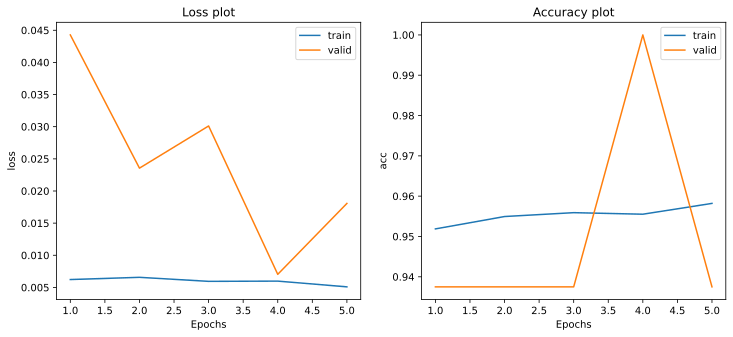

In [ ]:
# plot the model loss and accuracy
train_loss = history1.history['loss']
train_acc = history1.history['accuracy']

valid_loss = history1.history['val_loss']
valid_acc = history1.history['val_accuracy']

x = [(i+1) for i in range(len(train_loss))]

f,ax = plt.subplots(1,2, figsize=(12,5))
ax[0].plot(x, train_loss)
ax[0].plot(x, valid_loss)
ax[0].set_title("Loss plot")
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel("loss")
ax[0].legend(['train', 'valid'])


ax[1].plot(x, train_acc)
ax[1].plot(x, valid_acc)
ax[1].set_title("Accuracy plot")
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel("acc")
ax[1].legend(['train', 'valid'])

plt.show()

In [ ]:
# evaluate on test set
test_loss, test_acc = model.evaluate(test_data, test_labels, batch_size=batch_size)
print("Test loss: ", test_loss)
print(f"Test set accuracy: {test_acc*100:.2f}%")

39/39 [==============================] - 70s 2s/step - loss: 0.0804 - accuracy: 0.8782
Test loss:  0.08038175106048584
Test set accuracy: 87.82%


In [ ]:
# Get the predictions on test set
preds = model.predict(test_data, batch_size=16)
preds = np.squeeze((preds > 0.5).astype('int'))
orig = test_labels.astype('int')

39/39 [==============================] - 70s 2s/step


<Figure size 640x480 with 0 Axes>

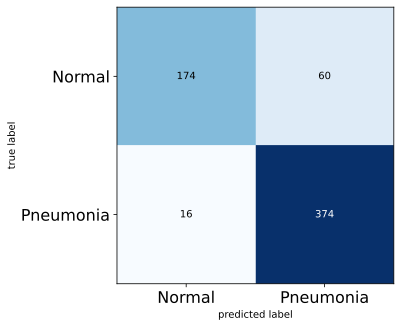

In [ ]:
# Get the confusion matrix
cm  = confusion_matrix(orig, preds)
plt.figure()
plot_confusion_matrix(cm,figsize=(10,5), hide_ticks=True, cmap=plt.cm.Blues)
plt.xticks(range(2), ['Normal', 'Pneumonia'], fontsize=16)
plt.yticks(range(2), ['Normal', 'Pneumonia'], fontsize=16)
plt.show()

In [ ]:
# Calculate Precision and Recall
tn, fp, fn, tp = cm.ravel()

precision = tp/(tp+fp)
recall = tp/(tp+fn)

print("Recall of the model is {:.2f}".format(recall))
print("Precision of the model is {:.2f}".format(precision))

Recall of the model is 0.96
Precision of the model is 0.86
